# Pruning

Based on **MIT 6.5940 EfficientML.ai Fall 2023: Lab 1 Pruning**

## Goals

In this assignment, you will practice pruning a classical neural network model to reduce both model size and latency. The goals of this assignment are as follows:

- Understand the basic concept of **pruning**
- Implement and apply **fine-grained pruning**
- Implement and apply **channel pruning**
- Get a basic understanding of performance improvement (such as speedup) from pruning
- Understand the differences and tradeoffs between these pruning approaches

## Contents

1. **Setup and dense model** — CIFAR-10, VGG, baseline accuracy and size.
2. **Fine-grained pruning** — magnitude-based selection, sensitivity, fine-tuning (Questions 1–5).
3. **Channel pruning** — channel removal, importance ranking, and latency (Questions 6–9).
4. **Iterative magnitude pruning** — progressive pruning with recovery training (Question 10).
5. **N:M (2:4) pruning** — semi-structured sparsity (Question 11).
6. **Attention-head pruning** — ablation-based selection using a small attention layer (Question 12).
7. **Activation-aware pruning** — Wanda importance scores on a small linear layer (Question 13).
8. **Further reading** — AutoML for Model Compression and the PyTorch Performance Tuning Guide.

## Setup

First, install the required packages and download the datasets and pretrained model. Here we use CIFAR10 dataset and VGG network which is the same as what we used in the Lab 0 tutorial.

In [1]:
print('Installing torchprofile...')
!pip install torchprofile 1>/dev/null
print('All required packages have been successfully installed!')

Installing torchprofile...
All required packages have been successfully installed!


In [2]:
import copy
import math
import random
import time
from collections import OrderedDict, defaultdict
from typing import Union, List

import numpy as np
import torch
from matplotlib import pyplot as plt
from torch import nn
from torch.optim import *
from torch.optim.lr_scheduler import *
from torch.utils.data import DataLoader
from torchprofile import profile_macs
from torchvision.datasets import *
from torchvision.transforms import *
from tqdm.auto import tqdm

from torchprofile import profile_macs

assert torch.cuda.is_available(), \
"The current runtime does not have CUDA support." \
"Please go to menu bar (Runtime - Change runtime type) and select GPU"

In [3]:
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

In [4]:
def download_url(url, model_dir='.', overwrite=False):
    import os, sys, ssl
    from urllib.request import urlretrieve
    ssl._create_default_https_context = ssl._create_unverified_context
    target_dir = url.split('/')[-1]
    model_dir = os.path.expanduser(model_dir)
    try:
        if not os.path.exists(model_dir):
            os.makedirs(model_dir)
        model_dir = os.path.join(model_dir, target_dir)
        cached_file = model_dir
        if not os.path.exists(cached_file) or overwrite:
            sys.stderr.write('Downloading: "{}" to {}\n'.format(url, cached_file))
            urlretrieve(url, cached_file)
        return cached_file
    except Exception as e:
        # remove lock file so download can be executed next time.
        os.remove(os.path.join(model_dir, 'download.lock'))
        sys.stderr.write('Failed to download from url %s' % url + '\n' + str(e) + '\n')
        return None

In [5]:
class VGG(nn.Module):
  ARCH = [64, 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M']

  def __init__(self) -> None:
    super().__init__()

    layers = []
    counts = defaultdict(int)

    def add(name: str, layer: nn.Module) -> None:
      layers.append((f"{name}{counts[name]}", layer))
      counts[name] += 1

    in_channels = 3
    for x in self.ARCH:
      if x != 'M':
        # conv-bn-relu
        add("conv", nn.Conv2d(in_channels, x, 3, padding=1, bias=False))
        add("bn", nn.BatchNorm2d(x))
        add("relu", nn.ReLU(True))
        in_channels = x
      else:
        # maxpool
        add("pool", nn.MaxPool2d(2))

    self.backbone = nn.Sequential(OrderedDict(layers))
    self.classifier = nn.Linear(512, 10)

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    # backbone: [N, 3, 32, 32] => [N, 512, 2, 2]
    x = self.backbone(x)

    # avgpool: [N, 512, 2, 2] => [N, 512]
    x = x.mean([2, 3])

    # classifier: [N, 512] => [N, 10]
    x = self.classifier(x)
    return x

In [6]:
def train(
  model: nn.Module,
  dataloader: DataLoader,
  criterion: nn.Module,
  optimizer: Optimizer,
  scheduler: LambdaLR,
  callbacks = None
) -> None:
  model.train()

  for inputs, targets in tqdm(dataloader, desc='train', leave=False):
    # Move the data from CPU to GPU
    inputs = inputs.cuda()
    targets = targets.cuda()

    # Reset the gradients (from the last iteration)
    optimizer.zero_grad()

    # Forward inference
    outputs = model(inputs)
    loss = criterion(outputs, targets)

    # Backward propagation
    loss.backward()

    # Update optimizer and LR scheduler
    optimizer.step()
    scheduler.step()

    if callbacks is not None:
        for callback in callbacks:
            callback()

In [7]:
@torch.inference_mode()
def evaluate(
  model: nn.Module,
  dataloader: DataLoader,
  verbose=True,
) -> float:
  model.eval()

  num_samples = 0
  num_correct = 0

  for inputs, targets in tqdm(dataloader, desc="eval", leave=False,
                              disable=not verbose):
    # Move the data from CPU to GPU
    inputs = inputs.cuda()
    targets = targets.cuda()

    # Inference
    outputs = model(inputs)

    # Convert logits to class indices
    outputs = outputs.argmax(dim=1)

    # Update metrics
    num_samples += targets.size(0)
    num_correct += (outputs == targets).sum()

  return (num_correct / num_samples * 100).item()

Helper Functions (Flops, Model Size calculation, etc.)

In [8]:
def get_model_macs(model, inputs) -> int:
    return profile_macs(model, inputs)


def get_sparsity(tensor: torch.Tensor) -> float:
    """
    calculate the sparsity of the given tensor
        sparsity = #zeros / #elements = 1 - #nonzeros / #elements
    """
    return 1 - float(tensor.count_nonzero()) / tensor.numel()


def get_model_sparsity(model: nn.Module) -> float:
    """
    calculate the sparsity of the given model
        sparsity = #zeros / #elements = 1 - #nonzeros / #elements
    """
    num_nonzeros, num_elements = 0, 0
    for param in model.parameters():
        num_nonzeros += param.count_nonzero()
        num_elements += param.numel()
    return 1 - float(num_nonzeros) / num_elements

def get_num_parameters(model: nn.Module, count_nonzero_only=False) -> int:
    """
    calculate the total number of parameters of model
    :param count_nonzero_only: only count nonzero weights
    """
    num_counted_elements = 0
    for param in model.parameters():
        if count_nonzero_only:
            num_counted_elements += param.count_nonzero()
        else:
            num_counted_elements += param.numel()
    return num_counted_elements


def get_model_size(model: nn.Module, data_width=32, count_nonzero_only=False) -> int:
    """
    calculate the model size in bits
    :param data_width: #bits per element
    :param count_nonzero_only: only count nonzero weights
    """
    return get_num_parameters(model, count_nonzero_only) * data_width

Byte = 8
KiB = 1024 * Byte
MiB = 1024 * KiB
GiB = 1024 * MiB

Define misc functions for verification.

In [9]:
def test_fine_grained_prune(
    test_tensor=torch.tensor([[-0.46, -0.40, 0.39, 0.19, 0.37],
                              [0.00, 0.40, 0.17, -0.15, 0.16],
                              [-0.20, -0.23, 0.36, 0.25, 0.03],
                              [0.24, 0.41, 0.07, 0.13, -0.15],
                              [0.48, -0.09, -0.36, 0.12, 0.45]]),
    test_mask=torch.tensor([[True, True, False, False, False],
                            [False, True, False, False, False],
                            [False, False, False, False, False],
                            [False, True, False, False, False],
                            [True, False, False, False, True]]),
    target_sparsity=0.75, target_nonzeros=None):
    def plot_matrix(tensor, ax, title):
        ax.imshow(tensor.cpu().numpy() == 0, vmin=0, vmax=1, cmap='tab20c')
        ax.set_title(title)
        ax.set_yticklabels([])
        ax.set_xticklabels([])
        for i in range(tensor.shape[1]):
            for j in range(tensor.shape[0]):
                text = ax.text(j, i, f'{tensor[i, j].item():.2f}',
                                ha="center", va="center", color="k")

    test_tensor = test_tensor.clone()
    fig, axes = plt.subplots(1,2, figsize=(6, 10))
    ax_left, ax_right = axes.ravel()
    plot_matrix(test_tensor, ax_left, 'dense tensor')

    sparsity_before_pruning = get_sparsity(test_tensor)
    mask = fine_grained_prune(test_tensor, target_sparsity)
    sparsity_after_pruning = get_sparsity(test_tensor)
    sparsity_of_mask = get_sparsity(mask)

    plot_matrix(test_tensor, ax_right, 'sparse tensor')
    fig.tight_layout()
    plt.show()

    print('* Test fine_grained_prune()')
    print(f'    target sparsity: {target_sparsity:.2f}')
    print(f'        sparsity before pruning: {sparsity_before_pruning:.2f}')
    print(f'        sparsity after pruning: {sparsity_after_pruning:.2f}')
    print(f'        sparsity of pruning mask: {sparsity_of_mask:.2f}')

    if target_nonzeros is None:
        if test_mask.equal(mask):
            print('* Test passed.')
        else:
            print('* Test failed.')
    else:
        if mask.count_nonzero() == target_nonzeros:
            print('* Test passed.')
        else:
            print('* Test failed.')

Load the pretrained model and the CIFAR-10 dataset.

In [10]:
checkpoint_url = "https://hanlab18.mit.edu/files/course/labs/vgg.cifar.pretrained.pth"
checkpoint = torch.load(download_url(checkpoint_url), map_location="cpu")
model = VGG().cuda()
print(f"=> loading checkpoint '{checkpoint_url}'")
model.load_state_dict(checkpoint['state_dict'])
recover_model = lambda: model.load_state_dict(checkpoint['state_dict'])

Downloading: "https://hanlab18.mit.edu/files/course/labs/vgg.cifar.pretrained.pth" to ./vgg.cifar.pretrained.pth


=> loading checkpoint 'https://hanlab18.mit.edu/files/course/labs/vgg.cifar.pretrained.pth'


In [13]:
image_size = 32
transforms = {
    "train": Compose([
        RandomCrop(image_size, padding=4),
        RandomHorizontalFlip(),
        ToTensor(),
    ]),
    "test": ToTensor(),
}
dataset = {}
for split in ["train", "test"]:
  dataset[split] = CIFAR10(
    root="data/cifar10",
    train=(split == "train"),
    download=True,
    transform=transforms[split],
  )
dataloader = {}
for split in ['train', 'test']:
  dataloader[split] = DataLoader(
    dataset[split],
    batch_size=512,
    shuffle=(split == 'train'),
    num_workers=0,
    pin_memory=True,
  )

100%|██████████| 170M/170M [32:45<00:00, 86.7kB/s]


## Let's First Evaluate the Accuracy and Model Size of Dense Model

Neural networks have become ubiquitous in many applications. Here we have loaded a pretrained VGG model for classifying images in CIFAR10 dataset.

Let's first evaluate the accuracy and model size of this model.

In [14]:
dense_model_accuracy = evaluate(model, dataloader['test'])
dense_model_size = get_model_size(model)
print(f"dense model has accuracy={dense_model_accuracy:.2f}%")
print(f"dense model has size={dense_model_size/MiB:.2f} MiB")

eval:   0%|          | 0/20 [00:00<?, ?it/s]

dense model has accuracy=92.95%
dense model has size=35.20 MiB


While large neural networks are very powerful, their size consumes considerable storage, memory bandwidth, and computational resources.
As we can see from the results above, a model for the task as simple as classifying $32\times32$ images into 10 classes can be as large as 35 MiB.
For embedded mobile applications, these resource demands become prohibitive.

Therefore, neural network pruning is exploited to facilitates storage and transmission of mobile applications incorporating DNNs.

The goal of pruning is to reduce the model size while maintaining the accuracy.

## Let's see the distribution of weight values

Before we jump into pruning, let's see the distribution of weight values in the dense model.

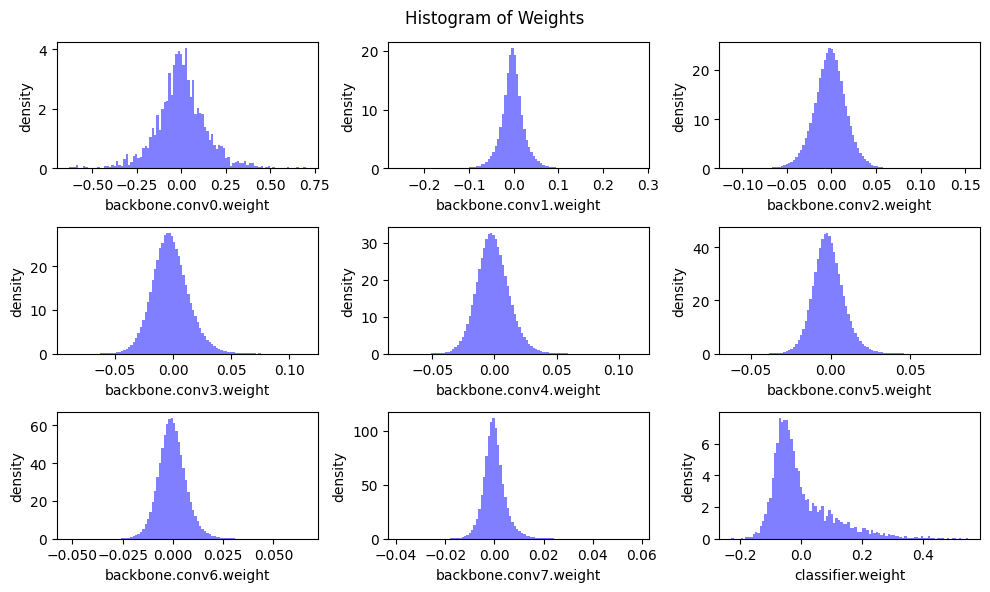

In [15]:
def plot_weight_distribution(model, bins=100, count_nonzero_only=False):
    fig, axes = plt.subplots(3,3, figsize=(10, 6))
    axes = axes.ravel()
    plot_index = 0
    for name, param in model.named_parameters():
        if param.dim() > 1:
            ax = axes[plot_index]
            if count_nonzero_only:
                param_cpu = param.detach().view(-1).cpu()
                param_cpu = param_cpu[param_cpu != 0].view(-1)
                ax.hist(param_cpu, bins=bins, density=True,
                        color = 'blue', alpha = 0.5)
            else:
                ax.hist(param.detach().view(-1).cpu(), bins=bins, density=True,
                        color = 'blue', alpha = 0.5)
            ax.set_xlabel(name)
            ax.set_ylabel('density')
            plot_index += 1
    fig.suptitle('Histogram of Weights')
    fig.tight_layout()
    fig.subplots_adjust(top=0.925)
    plt.show()

plot_weight_distribution(model)

## Question 1

Please answer the following questions using the information in the above histograms of weights.


### Question 1.1

What are the common characteristics of the weight distribution in the different layers?

**Your Answer:**

Most of the parameters of each layer are concentrated near zero. The distributions' variances are low, and model weights have small absolute values.

### Question 1.2

How do these characteristics help pruning?

**Your Answer:**

Since the majority of the parameters have near-zero values, many of them may be insignificant, which allows us to effectively prune them.

## Fine-grained Pruning

In this section, we will implement and perform fine-grained pruning.

Fine-grained pruning removes the synapses with lowest importance. The weight tensor $W$ will become sparse after fine-grained pruning, which can be described with **sparsity**:

> $\mathrm{sparsity} := \#\mathrm{Zeros} / \#W = 1 - \#\mathrm{Nonzeros} / \#W$

where $\#W$ is the number of elements in $W$.

In practice, given the target sparsity $s$, the weight tensor $W$ is multiplied with a binary mask $M$ to disregard removed weight:

> $v_{\mathrm{thr}} = \texttt{kthvalue}(Importance, \#W \cdot s)$
>
> $M = Importance > v_{\mathrm{thr}}$
>
> $W = W \cdot M$

where $Importance$ is importance tensor with the same shape of $W$, $\texttt{kthvalue}(X, k)$ finds the $k$-th smallest value of tensor $X$, $v_{\mathrm{thr}}$ is the threshold value.

![Illustration comparing removing individual connections and entire nodes](https://www.pokutta.com/blog/assets/bimp/pruning_difference.png)

**What to notice:** Removing individual connections produces **unstructured sparsity**, as in fine-grained pruning. Removing entire neurons produces **structured sparsity**. We first implement weight-level magnitude pruning, then study structured channel pruning in the next section. The figure illustrates pruning granularity, not how the importance scores are calculated.

*Source: [Max Zimmer, Christoph Spiegel and Sebastian Pokutta, *How I Learned to Stop Worrying and Love Retraining* (ICLR 2023 research summary)](https://www.pokutta.com/blog/research/2023/07/21/abstract-BIMP.html).*

## Magnitude-based Pruning

For fine-grained pruning, a widely-used importance is the magnitude of weight value, *i.e.*,

$Importance=|W|$

This is known as **Magnitude-based Pruning** (see [Learning both Weights and Connections for Efficient
Neural Networks](https://arxiv.org/pdf/1506.02626.pdf)).

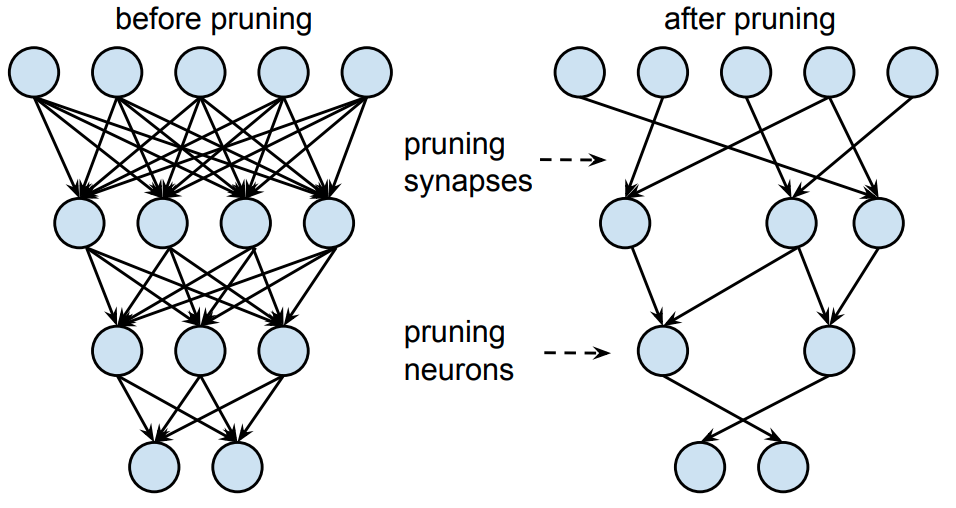

### Question 2

Please complete the following magnitude-based fine-grained pruning function.

**Hint**:
*   In step 1, we calculate the number of zeros (`num_zeros`) after pruning. Note that `num_zeros` should be an integer. You could use either `round()` or `int()` to convert a floating number into an integer. Here we use `round()`.
*   In step 2, we calculate the `importance` of weight tensor. Pytorch provides [`torch.abs()`](https://pytorch.org/docs/stable/generated/torch.abs.html#torch.abs), [`torch.Tensor.abs()`](https://pytorch.org/docs/stable/generated/torch.Tensor.abs.html#torch.Tensor.abs), [`torch.Tensor.abs_()`](https://pytorch.org/docs/stable/generated/torch.Tensor.abs_.html) APIs.
*   In step 3, we calculate the pruning `threshold` so that all synapses with importance smaller than `threshold` will be removed. Pytorch provides [`torch.kthvalue()`](https://pytorch.org/docs/stable/generated/torch.kthvalue.html), [`torch.Tensor.kthvalue()`](https://pytorch.org/docs/stable/generated/torch.Tensor.kthvalue.html), [`torch.topk()`](https://pytorch.org/docs/stable/generated/torch.topk.html) APIs.
*   In step 4, we calculate the pruning `mask` based on the `threshold`. **1** in the `mask` indicates the synapse will be kept, and **0** in the `mask` indicates the synapse will be removed. `mask = importance > threshold`. Pytorch provides [`torch.gt()`](https://pytorch.org/docs/stable/generated/torch.gt.html?highlight=torch%20gt#torch.gt) API.

In [16]:
def fine_grained_prune(tensor: torch.Tensor, sparsity : float) -> torch.Tensor:
    """
    magnitude-based pruning for single tensor
    :param tensor: torch.(cuda.)Tensor, weight of conv/fc layer
    :param sparsity: float, pruning sparsity
        sparsity = #zeros / #elements = 1 - #nonzeros / #elements
    :return:
        torch.(cuda.)Tensor, mask for zeros
    """
    sparsity = min(max(0.0, sparsity), 1.0)
    if sparsity == 1.0:
        tensor.zero_()
        return torch.zeros_like(tensor)
    elif sparsity == 0.0:
        return torch.ones_like(tensor)

    num_elements = tensor.numel()

    ##################### YOUR CODE STARTS HERE #####################
    # Step 1: calculate the #zeros (please use round())
    num_zeros = round(sparsity * num_elements)
    # Step 2: calculate the importance of weight
    importance = tensor.abs()
    # Step 3: calculate the pruning threshold
    threshold = importance.flatten().kthvalue(num_zeros).values
    # Step 4: get binary mask (1 for nonzeros, 0 for zeros)
    mask = importance > threshold
    ##################### YOUR CODE ENDS HERE #######################

    # Step 5: apply mask to prune the tensor
    tensor.mul_(mask)

    return mask

Let's verify the functionality of defined fine-grained pruning by applying the function above on a dummy tensor.

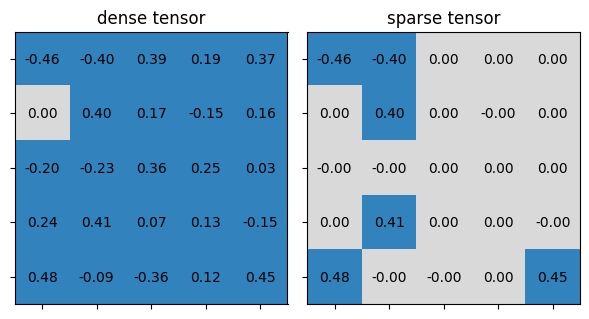

* Test fine_grained_prune()
    target sparsity: 0.75
        sparsity before pruning: 0.04
        sparsity after pruning: 0.76
        sparsity of pruning mask: 0.76
* Test passed.


In [17]:
test_fine_grained_prune()

### Question 3

The last cell plots the tensor before and after pruning. Nonzeros are rendered in blue while zeros are rendered in gray. Please modify the value of `target_sparsity` in the following code cell so that there are only 10 nonzeros in the sparse tensor after pruning.

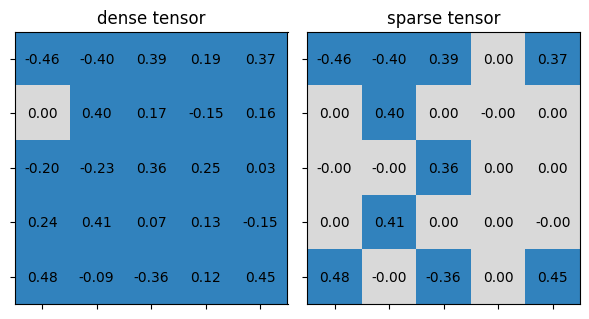

* Test fine_grained_prune()
    target sparsity: 0.60
        sparsity before pruning: 0.04
        sparsity after pruning: 0.60
        sparsity of pruning mask: 0.60
* Test passed.


In [18]:
##################### YOUR CODE STARTS HERE #####################
target_sparsity = 0.6 # please modify the value of target_sparsity
##################### YOUR CODE ENDS HERE #####################
test_fine_grained_prune(target_sparsity=target_sparsity, target_nonzeros=10)

We now wrap the fine-grained pruning function into a class for pruning the whole model. In class `FineGrainedPruner`, we have to keep a record of the pruning masks so that we could apply the masks whenever the model weights change to make sure the model keep sparse all the time.

In [19]:
class FineGrainedPruner:
    def __init__(self, model, sparsity_dict):
        self.masks = FineGrainedPruner.prune(model, sparsity_dict)

    @torch.no_grad()
    def apply(self, model):
        for name, param in model.named_parameters():
            if name in self.masks:
                param *= self.masks[name]

    @staticmethod
    @torch.no_grad()
    def prune(model, sparsity_dict):
        masks = dict()
        for name, param in model.named_parameters():
            if param.dim() > 1: # we only prune conv and fc weights
                masks[name] = fine_grained_prune(param, sparsity_dict[name])
        return masks

## Sensitivity Scan


Different layers contribute differently to the model performance. It is challenging to decide the proper sparsity for each layer. A widely used approach is sensitivity scan.

During the sensitivity scan, at each time, we will only prune one layer to see the accuracy degradation. By scanning different sparsities, we could draw the sensitivity curve (i.e., accuracy vs. sparsity) of the corresponding layer.

Here is an example figure for sensitivity curves. The x-axis is the sparsity or the percentage of #parameters dropped (*i.e.*, sparsity). The y-axis is the validation accuracy. (This is Figure 6 in [Learning both Weights and Connections for Efficient
Neural Networks](https://arxiv.org/pdf/1506.02626.pdf))


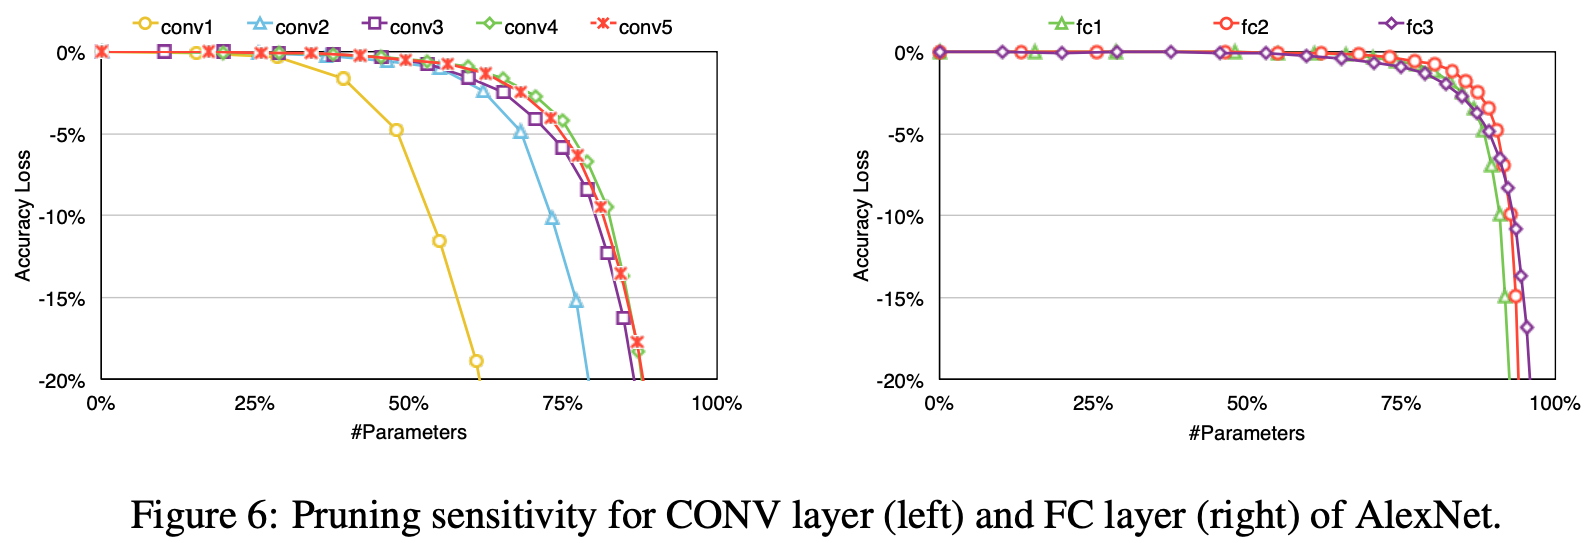

The following code cell defines the sensitivity scan function that returns the sparsities scanned, and a list of accuracies for each weight to be pruned.

In [20]:
@torch.no_grad()
def sensitivity_scan(model, dataloader, scan_step=0.1, scan_start=0.4, scan_end=1.0, verbose=True):
    sparsities = np.arange(start=scan_start, stop=scan_end, step=scan_step)
    accuracies = []
    named_conv_weights = [(name, param) for (name, param) \
                          in model.named_parameters() if param.dim() > 1]
    for i_layer, (name, param) in enumerate(named_conv_weights):
        param_clone = param.detach().clone()
        accuracy = []
        for sparsity in tqdm(sparsities, desc=f'scanning {i_layer}/{len(named_conv_weights)} weight - {name}'):
            fine_grained_prune(param.detach(), sparsity=sparsity)
            acc = evaluate(model, dataloader, verbose=False)
            if verbose:
                print(f'\r    sparsity={sparsity:.2f}: accuracy={acc:.2f}%', end='')
            # restore
            param.copy_(param_clone)
            accuracy.append(acc)
        if verbose:
            print(f'\r    sparsity=[{",".join(["{:.2f}".format(x) for x in sparsities])}]: accuracy=[{", ".join(["{:.2f}%".format(x) for x in accuracy])}]', end='')
        accuracies.append(accuracy)
    return sparsities, accuracies

Please run the following cells to plot the sensitivity curves. It should take around 2 minutes to finish.

In [ ]:
sparsities, accuracies = sensitivity_scan(
    model, dataloader['test'], scan_step=0.1, scan_start=0.4, scan_end=1.0)

scanning 0/9 weight - backbone.conv0.weight:   0%|          | 0/6 [00:00<?, ?it/s]

    sparsity=[0.40,0.50,0.60,0.70,0.80,0.90]: accuracy=[92.42%, 91.19%, 87.55%, 83.39%, 69.41%, 31.81%]

scanning 1/9 weight - backbone.conv1.weight:   0%|          | 0/6 [00:00<?, ?it/s]

    sparsity=[0.40,0.50,0.60,0.70,0.80,0.90]: accuracy=[92.93%, 92.88%, 92.71%, 92.40%, 91.32%, 84.78%]

scanning 2/9 weight - backbone.conv2.weight:   0%|          | 0/6 [00:00<?, ?it/s]

...

    sparsity=[0.40,0.50,0.60,0.70,0.80,0.90]: accuracy=[92.94%, 92.86%, 92.65%, 92.10%, 90.58%, 83.65%]

scanning 7/9 weight - backbone.conv7.weight:   0%|          | 0/6 [00:00<?, ?it/s]

    sparsity=[0.40,0.50,0.60,0.70,0.80,0.90]: accuracy=[92.94%, 92.92%, 92.88%, 92.81%, 92.63%, 91.34%]

scanning 8/9 weight - classifier.weight:   0%|          | 0/6 [00:00<?, ?it/s]

    sparsity=[0.40,0.50,0.60,0.70,0.80,0.90]: accuracy=[92.91%, 92.83%, 92.81%, 92.97%, 92.68%, 92.52%]

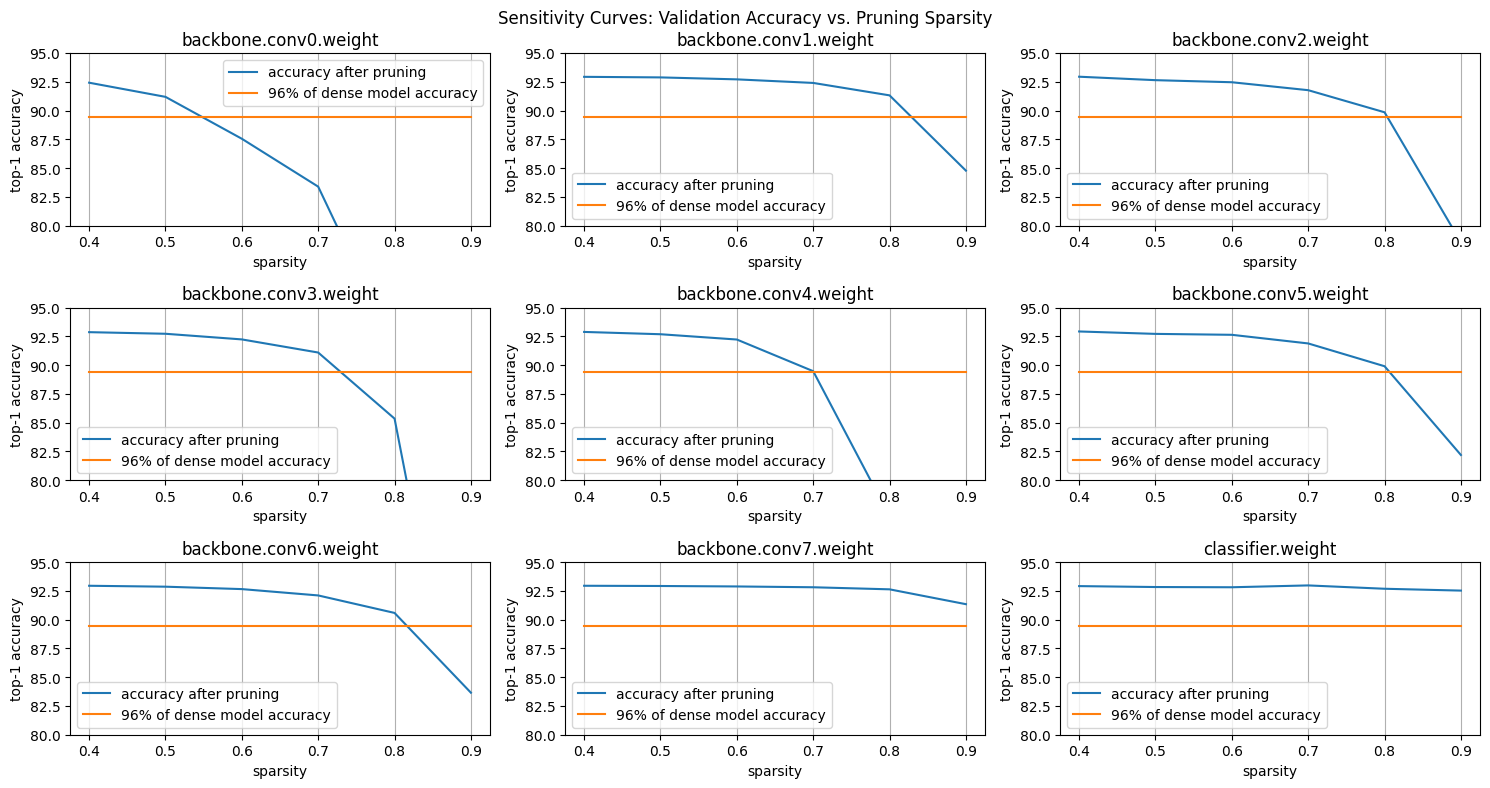

In [ ]:
def plot_sensitivity_scan(sparsities, accuracies, dense_model_accuracy):
    lower_bound_accuracy = 100 - (100 - dense_model_accuracy) * 1.5
    fig, axes = plt.subplots(3, int(math.ceil(len(accuracies) / 3)),figsize=(15,8))
    axes = axes.ravel()
    plot_index = 0
    for name, param in model.named_parameters():
        if param.dim() > 1:
            ax = axes[plot_index]
            curve = ax.plot(sparsities, accuracies[plot_index])
            line = ax.plot(sparsities, [lower_bound_accuracy] * len(sparsities))
            ax.set_xticks(np.arange(start=0.4, stop=1.0, step=0.1))
            ax.set_ylim(80, 95)
            ax.set_title(name)
            ax.set_xlabel('sparsity')
            ax.set_ylabel('top-1 accuracy')
            ax.legend([
                'accuracy after pruning',
                f'{lower_bound_accuracy / dense_model_accuracy * 100:.0f}% of dense model accuracy'
            ])
            ax.grid(axis='x')
            plot_index += 1
    fig.suptitle('Sensitivity Curves: Validation Accuracy vs. Pruning Sparsity')
    fig.tight_layout()
    fig.subplots_adjust(top=0.925)
    plt.show()

plot_sensitivity_scan(sparsities, accuracies, dense_model_accuracy)

### Question 4

Please answer the following questions using the information in the above sensitivity curves.

#### Question 4.1

What's the relationship between pruning sparsity and model accuracy? (*i.e.*, does accuracy increase or decrease when sparsity becomes higher?)

**Your Answer:**

When sparsity becomes higher model accuracy decreases, because a part of weights is no longer used during inference and, as a result, the model loses its precision.

#### Question 4.2

Do all the layers have the same sensitivity?

**Your Answer:**

No, the last convolution layer along with the classifier are much less sensitive than other layers. The greatest decline in accuracy is caused by pruning conv0 and conv4 layers.

#### Question 4.3

Which layer is the most sensitive to the pruning sparsity?

**Your Answer:**

It is the first convolution layer (conv0).

## \#Parameters of each layer
In addition to accuracy, the number of each layer's parameters also affects the decision on sparsity selection. Layers with more #parameters require larger sparsities.

Please run the following code cell to plot the distribution of #parameters in the whole model.

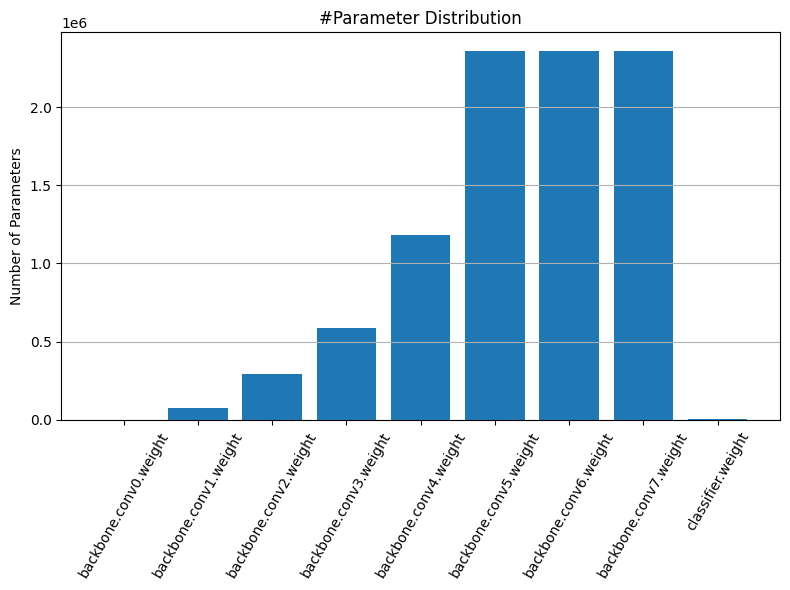

In [ ]:
def plot_num_parameters_distribution(model):
    num_parameters = dict()
    for name, param in model.named_parameters():
        if param.dim() > 1:
            num_parameters[name] = param.numel()
    fig = plt.figure(figsize=(8, 6))
    plt.grid(axis='y')
    plt.bar(list(num_parameters.keys()), list(num_parameters.values()))
    plt.title('#Parameter Distribution')
    plt.ylabel('Number of Parameters')
    plt.xticks(rotation=60)
    plt.tight_layout()
    plt.show()

plot_num_parameters_distribution(model)

## Select Sparsity Based on Sensitivity Curves and \#Parameters Distribution



### Question 5

Based on the sensitivity curves and the distribution of #parameters in the model, please select the sparsity for each layer.

Note that the overall compression ratio of pruned model mostly depends on the layers with larger #parameters, and different layers have different sensitivity to pruning (see Question 4).

Please make sure that after pruning, the sparse model is 25% of the size of the dense model, and validation accuracy is higher than 92.5 after finetuning.

**Hint**:
*   The layer with more #parameters should have larger sparsity. (see *Figure #Parameter Distribution*)
*   The layer that is sensitive to the pruning sparsity (i.e., the accuracy will drop quickly as sparsity becomes higher) should have smaller sparsity. (see *Figure Sensitivity Curves*)

In [ ]:
recover_model()

sparsity_dict = {
##################### YOUR CODE STARTS HERE #####################
    # please modify the sparsity value of each layer
    # please DO NOT modify the key of sparsity_dict
    'backbone.conv0.weight': 0.3,
    'backbone.conv1.weight': 0.4,
    'backbone.conv2.weight': 0.4,
    'backbone.conv3.weight': 0.5,
    'backbone.conv4.weight': 0.6,
    'backbone.conv5.weight': 0.8,
    'backbone.conv6.weight': 0.8,
    'backbone.conv7.weight': 0.85,
    'classifier.weight': 0.5
##################### YOUR CODE ENDS HERE #######################
}

Please run the following cell to prune the model according to your defined `sparsity_dict`, and print the information of sparse model.

After pruning with sparsity dictionary
  backbone.conv0.weight: 0.30
  backbone.conv1.weight: 0.40
  backbone.conv2.weight: 0.40
  backbone.conv3.weight: 0.50
  backbone.conv4.weight: 0.60
  backbone.conv5.weight: 0.80
  backbone.conv6.weight: 0.80
  backbone.conv7.weight: 0.85
  classifier.weight: 0.50
The sparsity of each layer becomes
  backbone.conv0.weight: 0.30
  backbone.conv1.weight: 0.40
  backbone.conv2.weight: 0.40
  backbone.conv3.weight: 0.50
  backbone.conv4.weight: 0.60
  backbone.conv5.weight: 0.80
  backbone.conv6.weight: 0.80
  backbone.conv7.weight: 0.85
  classifier.weight: 0.50
Sparse model has size=8.75 MiB = 24.87% of dense model size


eval:   0%|          | 0/20 [00:00<?, ?it/s]

Sparse model has accuracy=88.37% before fintuning


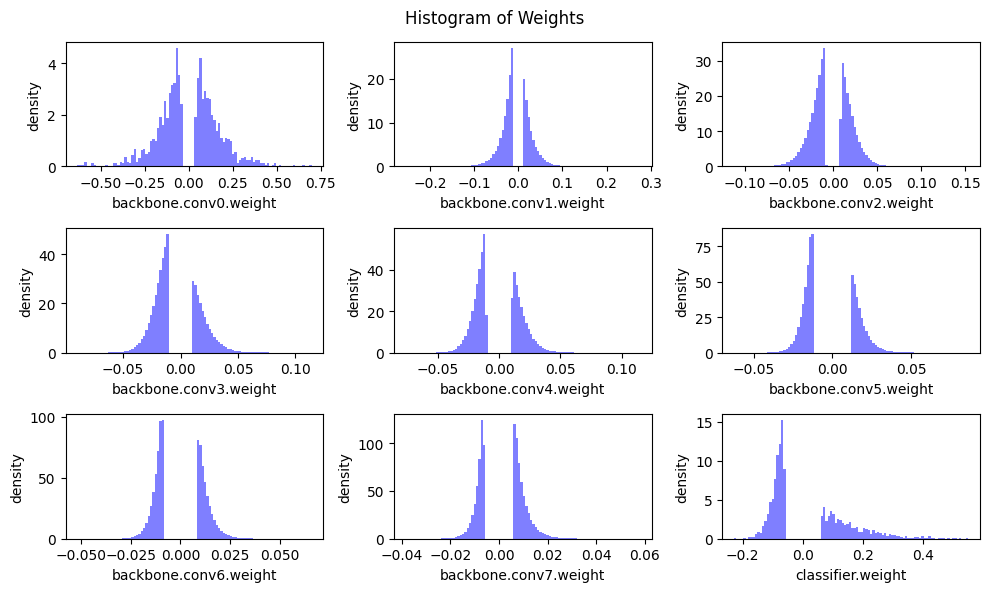

In [ ]:
pruner = FineGrainedPruner(model, sparsity_dict)
print(f'After pruning with sparsity dictionary')
for name, sparsity in sparsity_dict.items():
    print(f'  {name}: {sparsity:.2f}')
print(f'The sparsity of each layer becomes')
for name, param in model.named_parameters():
    if name in sparsity_dict:
        print(f'  {name}: {get_sparsity(param):.2f}')

sparse_model_size = get_model_size(model, count_nonzero_only=True)
print(f"Sparse model has size={sparse_model_size / MiB:.2f} MiB = {sparse_model_size / dense_model_size * 100:.2f}% of dense model size")
sparse_model_accuracy = evaluate(model, dataloader['test'])
print(f"Sparse model has accuracy={sparse_model_accuracy:.2f}% before fintuning")

plot_weight_distribution(model, count_nonzero_only=True)

## Finetune the fine-grained pruned model

As we can see from the outputs of previous cell, even though fine-grained pruning reduces the most of model weights, the accuracy of model also dropped. Therefore, we have to finetune the sparse model to recover the accuracy.

Please run the following cell to finetune the sparse model. It should take around 3 minutes to finish.

In [ ]:
num_finetune_epochs = 5
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, num_finetune_epochs)
criterion = nn.CrossEntropyLoss()

best_sparse_model_checkpoint = dict()
best_accuracy = 0
print(f'Finetuning Fine-grained Pruned Sparse Model')
for epoch in range(num_finetune_epochs):
    # At the end of each train iteration, we have to apply the pruning mask
    #    to keep the model sparse during the training
    train(model, dataloader['train'], criterion, optimizer, scheduler,
          callbacks=[lambda: pruner.apply(model)])
    accuracy = evaluate(model, dataloader['test'])
    is_best = accuracy > best_accuracy
    if is_best:
        best_sparse_model_checkpoint['state_dict'] = copy.deepcopy(model.state_dict())
        best_accuracy = accuracy
    print(f'    Epoch {epoch+1} Accuracy {accuracy:.2f}% / Best Accuracy: {best_accuracy:.2f}%')

Finetuning Fine-grained Pruned Sparse Model


train:   0%|          | 0/98 [00:00<?, ?it/s]

eval:   0%|          | 0/20 [00:00<?, ?it/s]

    Epoch 1 Accuracy 92.45% / Best Accuracy: 92.45%


train:   0%|          | 0/98 [00:00<?, ?it/s]

...

eval:   0%|          | 0/20 [00:00<?, ?it/s]

    Epoch 4 Accuracy 92.85% / Best Accuracy: 92.88%


train:   0%|          | 0/98 [00:00<?, ?it/s]

eval:   0%|          | 0/20 [00:00<?, ?it/s]

    Epoch 5 Accuracy 92.76% / Best Accuracy: 92.88%


Run the following cell to see the information of best finetuned sparse model.

In [ ]:
# load the best sparse model checkpoint to evaluate the final performance
model.load_state_dict(best_sparse_model_checkpoint['state_dict'])
sparse_model_size = get_model_size(model, count_nonzero_only=True)
print(f"Sparse model has size={sparse_model_size / MiB:.2f} MiB = {sparse_model_size / dense_model_size * 100:.2f}% of dense model size")
sparse_model_accuracy = evaluate(model, dataloader['test'])
print(f"Sparse model has accuracy={sparse_model_accuracy:.2f}% after fintuning")

Sparse model has size=8.75 MiB = 24.87% of dense model size


eval:   0%|          | 0/20 [00:00<?, ?it/s]

Sparse model has accuracy=92.88% after fintuning


## Channel Pruning

In this section, we will implement the channel pruning. Channel pruning removes an entire channel, so that it can achieve inference speed up on existing hardware like GPUs. Similarly, we remove the channels whose weights are of smaller magnitudes (measured by Frobenius norm).

![Diagram of convolutional filter pruning and reduced tensors](https://seongkyun.github.io/assets/post_img/papers/2019-04-15-pruning_ssd/fig1.jpg)

**What to notice:** The figure shows a convolutional pruning workflow: selecting fewer filters changes the **output channels** of one layer and the corresponding **input channels** of the next. Simply writing zeros into a full-sized tensor does not achieve this dense-model shape reduction.

*Source: [Seongkyun Han et al., *Multi-layer Pruning Framework for Compressing Single Shot MultiBox Detector*](https://seongkyun.github.io/papers/2019/04/15/pruning_ssd/).*

In [ ]:
# firstly, let's restore the model weights to the original dense version
#   and check the validation accuracy
recover_model()
dense_model_accuracy = evaluate(model, dataloader['test'])
print(f"dense model has accuracy={dense_model_accuracy:.2f}%")

eval:   0%|          | 0/20 [00:00<?, ?it/s]

dense model has accuracy=92.95%


## Remove Channel Weights

Unlike fine-grained pruning, we can remove the weights entirely from the tensor in channel pruning. That is to say, the number of output channels is reduced:

> $\#\mathrm{out\_channels}_{\mathrm{new}} = \#\mathrm{out\_channels}_{\mathrm{origin}} \cdot (1 - \mathrm{sparsity})$

The weight tensor $W$ is still dense after channel pruning. Thus, we will refer to *sparsity* as ***prune ratio***.

Like fine-grained pruning, we can use different pruning rates for different layers. However, we use a uniform pruning rate for all the layers for now. We are targeting 2x computation reduction, which is roughly 30% uniform pruning rate (think about why).

Feel free to try out different pruning ratios per layer at the end of this section. You can pass in a list of ratios to the `channel_prune` function.

### Question 6

Please complete the following functions for channel pruning.

Here we naively prune all output channels other than the first $\#\mathrm{out\_channels}_{\mathrm{new}}$ channels.

In [ ]:
def get_num_channels_to_keep(channels: int, prune_ratio: float) -> int:
    """A function to calculate the number of layers to PRESERVE after pruning
    Note that preserve_rate = 1. - prune_ratio
    """
    ##################### YOUR CODE STARTS HERE #####################
    return channels - round(channels * prune_ratio)
    ##################### YOUR CODE ENDS HERE #####################

@torch.no_grad()
def channel_prune(model: nn.Module,
                  prune_ratio: Union[List, float]) -> nn.Module:
    """Apply channel pruning to each of the conv layer in the backbone
    Note that for prune_ratio, we can either provide a floating-point number,
    indicating that we use a uniform pruning rate for all layers, or a list of
    numbers to indicate per-layer pruning rate.
    """
    # sanity check of provided prune_ratio
    assert isinstance(prune_ratio, (float, list))
    n_conv = len([m for m in model.backbone if isinstance(m, nn.Conv2d)])
    # note that for the ratios, it affects the previous conv output and next
    # conv input, i.e., conv0 - ratio0 - conv1 - ratio1-...
    if isinstance(prune_ratio, list):
        assert len(prune_ratio) == n_conv - 1
    else:  # convert float to list
        prune_ratio = [prune_ratio] * (n_conv - 1)

    # we prune the convs in the backbone with a uniform ratio
    model = copy.deepcopy(model)  # prevent overwrite
    # we only apply pruning to the backbone features
    all_convs = [m for m in model.backbone if isinstance(m, nn.Conv2d)]
    all_bns = [m for m in model.backbone if isinstance(m, nn.BatchNorm2d)]
    # apply pruning. we naively keep the first k channels
    assert len(all_convs) == len(all_bns)
    for i_ratio, p_ratio in enumerate(prune_ratio):
        prev_conv = all_convs[i_ratio]
        prev_bn = all_bns[i_ratio]
        next_conv = all_convs[i_ratio + 1]
        original_channels = prev_conv.out_channels  # same as next_conv.in_channels
        n_keep = get_num_channels_to_keep(original_channels, p_ratio)

        # prune the output of the previous conv and bn
        prev_conv.weight.set_(prev_conv.weight.detach()[:n_keep])
        prev_bn.weight.set_(prev_bn.weight.detach()[:n_keep])
        prev_bn.bias.set_(prev_bn.bias.detach()[:n_keep])
        prev_bn.running_mean.set_(prev_bn.running_mean.detach()[:n_keep])
        prev_bn.running_var.set_(prev_bn.running_var.detach()[:n_keep])

        # prune the input of the next conv (hint: just one line of code)
        ##################### YOUR CODE STARTS HERE #####################
        next_conv.weight.set_(next_conv.weight.detach()[:, :n_keep])
        ##################### YOUR CODE ENDS HERE #####################

    return model


Run the following cell to perform a sanity check to make sure the implementation is correct.

In [ ]:
dummy_input = torch.randn(1, 3, 32, 32).cuda()
pruned_model = channel_prune(model, prune_ratio=0.3)
pruned_macs = get_model_macs(pruned_model, dummy_input)
assert pruned_macs == 305388064
print('* Check passed. Right MACs for the pruned model.')

* Check passed. Right MACs for the pruned model.


Now let's evaluate the performance of the model after uniform channel pruning with 30% pruning rate.

As you may see, directly removing 30% of the channels leads to low accuracy.

In [ ]:
pruned_model_accuracy = evaluate(pruned_model, dataloader['test'])
print(f"pruned model has accuracy={pruned_model_accuracy:.2f}%")

eval:   0%|          | 0/20 [00:00<?, ?it/s]

pruned model has accuracy=28.14%


## Ranking Channels by Importance

As you can see, removing the first 30% of channels in all layers leads to significant accuracy reduction. One potential method to remedy the issue is to find the **less important** channel weights to remove. A popular criterion for importance is to use the Frobenius norm of the weights corresponding to each input channel:

> $importance_{i} = \|W_{i}\|_2, \;\; i = 0, 1, 2,\cdots, \#\mathrm{in\_channels}-1$

We can sort the channel weights from more important to less important, and then keep the frst $k$ channels for each layer.

### Question 7
Please complete the following functions for sorting the weight tensor based on the Frobenius norm.

**Hint**:
* To calculate Frobenius norm of a tensor, Pytorch provides [`torch.norm`](https://pytorch.org/docs/master/generated/torch.norm.html?highlight=torch+norm#torch.norm) APIs.

In [ ]:
# function to sort the channels from important to non-important
def get_input_channel_importance(weight):
    in_channels = weight.shape[1]
    importances = []
    # compute the importance for each input channel
    for i_c in range(weight.shape[1]):
        channel_weight = weight.detach()[:, i_c]
        ##################### YOUR CODE STARTS HERE #####################
        importance = torch.norm(channel_weight, p='fro')
        ##################### YOUR CODE ENDS HERE #####################
        importances.append(importance.view(1))
    return torch.cat(importances)

@torch.no_grad()
def apply_channel_sorting(model):
    model = copy.deepcopy(model)  # do not modify the original model
    # fetch all the conv and bn layers from the backbone
    all_convs = [m for m in model.backbone if isinstance(m, nn.Conv2d)]
    all_bns = [m for m in model.backbone if isinstance(m, nn.BatchNorm2d)]
    # iterate through conv layers
    for i_conv in range(len(all_convs) - 1):
        # each channel sorting index, we need to apply it to:
        # - the output dimension of the previous conv
        # - the previous BN layer
        # - the input dimension of the next conv (we compute importance here)
        prev_conv = all_convs[i_conv]
        prev_bn = all_bns[i_conv]
        next_conv = all_convs[i_conv + 1]
        # note that we always compute the importance according to input channels
        importance = get_input_channel_importance(next_conv.weight)
        # sorting from large to small
        sort_idx = torch.argsort(importance, descending=True)

        # apply to previous conv and its following bn
        prev_conv.weight.copy_(torch.index_select(
            prev_conv.weight.detach(), 0, sort_idx))
        for tensor_name in ['weight', 'bias', 'running_mean', 'running_var']:
            tensor_to_apply = getattr(prev_bn, tensor_name)
            tensor_to_apply.copy_(
                torch.index_select(tensor_to_apply.detach(), 0, sort_idx)
            )

        # apply to the next conv input (hint: one line of code)
        ##################### YOUR CODE STARTS HERE #####################
        next_conv.weight.copy_(torch.index_select(next_conv.weight.detach(), 1, sort_idx))
        ##################### YOUR CODE ENDS HERE #####################

    return model

Now run the following cell to sanity check if the results are correct.

In [ ]:
print('Before sorting...')
dense_model_accuracy = evaluate(model, dataloader['test'])
print(f"dense model has accuracy={dense_model_accuracy:.2f}%")

print('After sorting...')
sorted_model = apply_channel_sorting(model)
sorted_model_accuracy = evaluate(sorted_model, dataloader['test'])
print(f"sorted model has accuracy={sorted_model_accuracy:.2f}%")

# make sure accuracy does not change after sorting, since it is
# equivalent transform
assert abs(sorted_model_accuracy - dense_model_accuracy) < 0.1
print('* Check passed.')

Before sorting...


eval:   0%|          | 0/20 [00:00<?, ?it/s]

dense model has accuracy=92.95%
After sorting...


eval:   0%|          | 0/20 [00:00<?, ?it/s]

sorted model has accuracy=92.95%
* Check passed.


Finally, we compare the pruned models' accuracy with and without sorting.

In [ ]:
channel_pruning_ratio = 0.3  # pruned-out ratio

print(" * Without sorting...")
pruned_model = channel_prune(model, channel_pruning_ratio)
pruned_model_accuracy = evaluate(pruned_model, dataloader['test'])
print(f"pruned model has accuracy={pruned_model_accuracy:.2f}%")


print(" * With sorting...")
sorted_model = apply_channel_sorting(model)
pruned_model = channel_prune(sorted_model, channel_pruning_ratio)
pruned_model_accuracy = evaluate(pruned_model, dataloader['test'])
print(f"pruned model has accuracy={pruned_model_accuracy:.2f}%")


 * Without sorting...


eval:   0%|          | 0/20 [00:00<?, ?it/s]

pruned model has accuracy=28.14%
 * With sorting...


eval:   0%|          | 0/20 [00:00<?, ?it/s]

pruned model has accuracy=36.81%


As you can see, the channel sorting can slightly improve the pruned model's accuracy, but there is still a huge degrade, which is quite common for channel pruning. But luckily, we can perform fine-tuning to recover the accuracy.

In [ ]:
num_finetune_epochs = 5
optimizer = torch.optim.SGD(pruned_model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, num_finetune_epochs)
criterion = nn.CrossEntropyLoss()

best_accuracy = 0
for epoch in range(num_finetune_epochs):
    train(pruned_model, dataloader['train'], criterion, optimizer, scheduler)
    accuracy = evaluate(pruned_model, dataloader['test'])
    is_best = accuracy > best_accuracy
    if is_best:
        best_accuracy = accuracy
    print(f'Epoch {epoch+1} Accuracy {accuracy:.2f}% / Best Accuracy: {best_accuracy:.2f}%')

train:   0%|          | 0/98 [00:00<?, ?it/s]

eval:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1 Accuracy 91.50% / Best Accuracy: 91.50%


train:   0%|          | 0/98 [00:00<?, ?it/s]

eval:   0%|          | 0/20 [00:00<?, ?it/s]

...

eval:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 4 Accuracy 92.12% / Best Accuracy: 92.14%


train:   0%|          | 0/98 [00:00<?, ?it/s]

eval:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 5 Accuracy 92.26% / Best Accuracy: 92.26%


## Measure acceleration from pruning

After fine-tuning, the model almost recovers the accuracy. You may have already learned that channel pruning is usually more difficult to recover accuracy compared to fine-grained pruning. However, it directly leads to a smaller model size and smaller computation without specialized model format. It can also run faster on GPUs. Now we compare the model size, computation, and latency of the pruned model.

In [ ]:
# helper functions to measure latency of a regular PyTorch models.
#   Unlike fine-grained pruning, channel pruning
#   can directly leads to model size reduction and speed up.
@torch.no_grad()
def measure_latency(model, dummy_input, n_warmup=20, n_test=100):
    model.eval()
    # warmup
    for _ in range(n_warmup):
        _ = model(dummy_input)
    # real test
    t1 = time.time()
    for _ in range(n_test):
        _ = model(dummy_input)
    t2 = time.time()
    return (t2 - t1) / n_test  # average latency

table_template = "{:<15} {:<15} {:<15} {:<15}"
print (table_template.format('', 'Original','Pruned','Reduction Ratio'))

# 1. measure the latency of the original model and the pruned model on CPU
#   which simulates inference on an edge device
dummy_input = torch.randn(1, 3, 32, 32).to('cpu')
pruned_model = pruned_model.to('cpu')
model = model.to('cpu')

pruned_latency = measure_latency(pruned_model, dummy_input)
original_latency = measure_latency(model, dummy_input)
print(table_template.format('Latency (ms)',
                            round(original_latency * 1000, 1),
                            round(pruned_latency * 1000, 1),
                            round(original_latency / pruned_latency, 1)))

# 2. measure the computation (MACs)
original_macs = get_model_macs(model, dummy_input)
pruned_macs = get_model_macs(pruned_model, dummy_input)
print(table_template.format('MACs (M)',
                            round(original_macs / 1e6),
                            round(pruned_macs / 1e6),
                            round(original_macs / pruned_macs, 1)))

# 3. measure the model size (params)
original_param = get_num_parameters(model)
pruned_param = get_num_parameters(pruned_model)
print(table_template.format('Param (M)',
                            round(original_param / 1e6, 2),
                            round(pruned_param / 1e6, 2),
                            round(original_param / pruned_param, 1)))

# put model back to cuda
pruned_model = pruned_model.to('cuda')
model = model.to('cuda')

                Original        Pruned          Reduction Ratio
Latency (ms)    18.0            11.0            1.6            
MACs (M)        606             305             2.0            
Param (M)       9.23            5.01            1.8            


### Question 8

Please answer the following questions using the information in the previous code cell.


In [ ]:
(64*0.7*3+128*0.49*64+256*0.49*128+256*0.49*256+512*0.49*256+512*0.7*512) / \
(64*3+128*64+256*128+256*256+512*256+512*512)

0.6002022788375369

#### Question 8.1

Explain why removing 30% of channels roughly leads to 50% computation reduction.

**Your Answer:**

Almost each convolution layer (except for the first and the last ones) is reduced by 0.49 times, because the number of output channels of a layer equals to the number of input channels of the next layer. Pooling also requires 0.49 times less calculations. That gives us the 50% computation reduction.

#### Question 8.2

Explain why the latency reduction ratio is slightly smaller than computation reduction.

**Your Answer:**

Latency is not directly proportional to computation, because it is also influenced by some other factors such as memory access, GPU utilization and so on.

## Compare Fine-grained Pruning and Channel Pruning


## Question 9


After all experiments in this lab, you may have become familiar with both fine-grained pruning and channel pruning.

Please answer the following questions using what you have learned from the lectures and this lab.

### Question 9.1

What are the advantages and disadvantages of fine-grained pruning and channel pruning? You can discuss from the perspective of compression ratio, accuracy, latency, hardware support (*i.e.*, requiring specialized hardware accelerator), etc.

**Your Answer:**

Fine-grained pruning is simpler and may be applied easily to every model. Besides, if done correctly, it doesn't significantly decline test accuracy. Channel pruning is more difficult, requires additional precumputations and fine tuning, because test accuracy considerably drops. Nevertheless, fine-grained pruning only zeros a part of model weights and doesn't reduce neither model size nor computation time, while channel pruning really compresses the model and provides inference acceleration and less memory consumption.

### Question 9.2

If you want to make your model run faster on a smartphone, which pruning method will you use? Why?



**Your Answer:**

I would use channel pruning, because my model has to be compact and fast to fit in the phone memory and produce low latency.

## Further Pruning Techniques

The following exercises explore pruning schedules, structured sparsity, and importance scores for attention and linear layers.

- Iterative magnitude pruning with fine-tuning between stages.
- N:M (2:4) semi-structured pruning.
- Attention-head pruning using four attention heads.
- Activation-aware pruning using calibration inputs.

## Iterative Magnitude Pruning

Magnitude pruning (Question 2) removes small-magnitude weights in one step. **Iterative magnitude pruning** alternates pruning with recovery training:

$$0\%\;\longrightarrow\;25\%\;\xrightarrow{\text{train}}\;50\%\;\xrightarrow{\text{train}}\;75\%\;\xrightarrow{\text{train}}$$

The importance score remains $|w|$, but the remaining weights can adapt between pruning stages. Previously removed weights must stay zero, including after optimizer updates.

Compare one-shot pruning to 75% sparsity with three pruning stages using the **same total number of recovery-training updates**.

![Pruning and retraining stages](https://www.merl.com/research/highlights/green-ai/media/Figure17.jpg)

**Explanation:** Weight removal alternates with recovery training. At each stage, the surviving weights are updated before the next pruning step.

*Source: [Mitsubishi Electric Research Laboratories, Sustainable AI](https://www.merl.com/research/highlights/green-ai).*

### Question 10

Complete `iterative_magnitude_prune` so that a new target sparsity removes additional weights **without regrowth**.

**Hint**:
* Start with an all-ones Boolean mask if there is no previous mask.
* Exclude previously removed weights using `-float('inf')` before `topk`.
* Calculate how many weights should remain at the **total requested sparsity** (not the fraction to remove from what remains).
* Never increase the number of active weights.


In [ ]:
@torch.no_grad()
def iterative_magnitude_prune(tensor: torch.Tensor,
                              target_sparsity: float,
                              previous_mask=None) -> torch.Tensor:
    """Prune to an overall target sparsity; never restore removed weights."""
    target_sparsity = min(max(float(target_sparsity), 0.0), 1.0)
    if previous_mask is None:
        previous_mask = torch.ones_like(tensor, dtype=torch.bool)
    previous_mask = previous_mask.bool()
    num_elements = tensor.numel()

    ##################### YOUR CODE STARTS HERE #####################
    # Step 1: count the weights to keep at the target sparsity.
    #         Never keep more than the number still active.
    num_active = previous_mask.sum()
    num_keep = num_elements - round(target_sparsity * num_elements)


    # Step 2: rank surviving weights by absolute magnitude.
    #         Exclude previously pruned weights with -inf.

    importance = torch.where(previous_mask, tensor.abs(), -float('inf'))
    threshold = importance.flatten().topk(num_keep).values[-1]

    # Step 3: create a new Boolean mask with exactly num_keep entries.
    new_mask = importance >= threshold
    ##################### YOUR CODE ENDS HERE #######################

    tensor.mul_(new_mask)
    return new_mask


Test the masks on a tiny $4\times 4$ tensor.


In [ ]:
# Check that masks are monotone and reach the requested sparsity.
iterative_tensor = torch.arange(1, 17, dtype=torch.float32).reshape(4, 4)
previous_mask = None
for target_sparsity in [0.25, 0.50, 0.75]:
    old_mask = previous_mask
    previous_mask = iterative_magnitude_prune(
        iterative_tensor, target_sparsity, previous_mask)
    assert previous_mask.dtype == torch.bool
    assert abs(get_sparsity(iterative_tensor) - target_sparsity) < 1e-6
    if old_mask is not None:
        assert not (previous_mask & ~old_mask).any()
    print(f'target={target_sparsity:.0%}; active weights={previous_mask.sum().item()}')
print('* Mask test passed.')


target=25%; active weights=12
target=50%; active weights=8
target=75%; active weights=4
* Mask test passed.


### Question 10.1

Complete `train_pruned_linear` so that pruning is **maintained during gradient-based recovery training**.

**Hint**: Use `loss.backward()`, `optimizer.step()`, then `layer.weight.mul_(mask)` under `torch.no_grad()`. Do not zero the gradients *instead of* reapplying the weight mask.


In [ ]:
def train_pruned_linear(layer, inputs, targets, mask, steps=60, lr=0.10):
    """Train a tiny linear layer while forcing pruned weights to remain zero."""
    optimizer = torch.optim.SGD(layer.parameters(), lr=lr)
    for _ in range(steps):
        optimizer.zero_grad()
        predictions = layer(inputs)
        loss = torch.nn.functional.mse_loss(predictions, targets)

        ##################### YOUR CODE STARTS HERE #####################
        # Step 1: calculate gradients and update the remaining weights
        loss.backward()
        optimizer.step()

        # Step 2: reapply the mask AFTER optimizer.step() so zero weights
        #         cannot regrow. Use torch.no_grad() for the in-place update.
        with torch.no_grad():
            layer.weight.mul_(mask)

        ##################### YOUR CODE ENDS HERE #######################
    return torch.nn.functional.mse_loss(layer(inputs), targets).item()


Run the following regression experiment. Both methods start from identical dense-model weights and receive **180 recovery updates**. Compare their final mean squared errors (MSEs).

In [ ]:
# Synthetic regression data for comparing pruning schedules.
import copy
import torch.nn.functional as F

torch.manual_seed(16)
toy_inputs = torch.randn(96, 12)
true_weights = torch.randn(3, 12)
toy_targets = F.linear(toy_inputs, true_weights) + 0.03 * torch.randn(96, 3)

# First train a small dense model. Both pruning strategies start from this state.
dense_layer = torch.nn.Linear(12, 3, bias=False)
_ = train_pruned_linear(dense_layer, toy_inputs, toy_targets,
                        torch.ones_like(dense_layer.weight, dtype=torch.bool),
                        steps=140)

# One-shot: prune directly to 75%, then fine-tune for 3 x 60 steps.
one_shot = copy.deepcopy(dense_layer)
one_mask = iterative_magnitude_prune(one_shot.weight, 0.75)
one_shot_before = F.mse_loss(one_shot(toy_inputs), toy_targets).item()
one_shot_after = train_pruned_linear(one_shot, toy_inputs, toy_targets,
                                     one_mask, steps=180)

# Iterative: 25% -> train -> 50% -> train -> 75% -> train.
iterative_layer = copy.deepcopy(dense_layer)
mask = None
for target_sparsity in [0.25, 0.50, 0.75]:
    mask = iterative_magnitude_prune(iterative_layer.weight, target_sparsity, mask)
    stage_loss = train_pruned_linear(iterative_layer, toy_inputs, toy_targets,
                                    mask, steps=60)
    assert torch.all(iterative_layer.weight[~mask] == 0)
    print(f'Iterative stage {target_sparsity:.0%}: MSE={stage_loss:.5f}')
iterative_after = F.mse_loss(iterative_layer(toy_inputs), toy_targets).item()

assert int(one_mask.sum()) == int(mask.sum())
print(f'One-shot (before recovery): MSE={one_shot_before:.5f}')
print(f'One-shot (after 180 steps): MSE={one_shot_after:.5f}')
print(f'Iterative (3 x 60 steps):   MSE={iterative_after:.5f}')
print('* Both methods use 180 recovery updates and the same final sparsity.')


Iterative stage 25%: MSE=0.22654
Iterative stage 50%: MSE=1.30114
Iterative stage 75%: MSE=3.01427
One-shot (before recovery): MSE=3.62843
One-shot (after 180 steps): MSE=3.55666
Iterative (3 x 60 steps):   MSE=3.01427
* Both methods use 180 recovery updates and the same final sparsity.


### Question 10.2

Why do we reapply the mask after every optimizer step? Is iterative pruning **guaranteed** to outperform one-shot pruning when both get the same training budget?


**Your Answer:**

We reapply the mask because optimizer step updates model parameters and previously zeroed weights can become nonzero, which is unacceptable in our pruning strategy. I think that iterative pruning is not guaranteed to outperform one-shot pruning, because with an equal training budget one-shot pruning trains the model only once and thus does it more thoroughly, while iterative pruning runs the training process several times and, consequently, shortens each training period, impeding the model from learning more patterns in the data.


## N:M Pruning (2:4)

Fine-grained pruning (Question 2) can remove weights at arbitrary positions. **N:M pruning** constrains pruning within fixed-size groups. In **2:4 pruning**, exactly two of every four weights are kept, usually those with the largest absolute values.

This pattern provides 50% sparsity in the pruned weight groups. Specialized kernels can exploit this structure, but zeroing weights in an ordinary dense PyTorch tensor does not automatically improve latency.

![Official PyTorch illustration of 2:4 semi-structured sparsity](https://pytorch.org/assets/images/accelerating-neural-network-training/fg2.png)

**What to notice:** Look for a fixed two-out-of-four pattern, rather than zeros at unrestricted positions. Compatible hardware can encode the pattern more efficiently.

*Source: [PyTorch, Accelerating Neural Network Training with Semi-Structured (2:4) Sparsity (2024)](https://pytorch.org/blog/accelerating-neural-network-training/).*


### Question 11

Complete `prune_2_4`. Each group of four is taken from the **last dimension**, and a group must never cross a row boundary.

**Hint**:
* The matrix has shape `[rows, features]` and `features % 4 == 0`.
* Reshape to `(-1, 4)` and use `topk(..., k=2, dim=1)`.
* Create the mask with `scatter_()` and reshape it back.


In [21]:
@torch.no_grad()
def prune_2_4(tensor: torch.Tensor) -> torch.Tensor:
    """Keep the two largest-magnitude weights in each group of four."""
    assert tensor.ndim == 2 and tensor.shape[1] % 4 == 0
    groups = tensor.reshape(-1, 4)

    ##################### YOUR CODE STARTS HERE #####################
    # Step 1: select the 2 most important positions per group
    keep_idx = groups.topk(2, dim=1).indices
    # Step 2: construct a Boolean mask for all groups
    group_mask = torch.zeros_like(groups).scatter_(dim=1, index=keep_idx, value=1)
    # Step 3: reshape to the original matrix shape
    mask = group_mask.reshape(-1, tensor.shape[1])
    ##################### YOUR CODE ENDS HERE #######################

    tensor.mul_(mask)
    return mask


Check that every group has exactly two retained positions.


In [22]:
nm_tensor = torch.tensor([
    [0.1, -2.0, 0.3, 4.0, 0.2, 1.0, -3.0, 0.4],
    [5.0, 0.1, -0.2, -6.0, 2.0, -3.0, 0.5, 0.1],
])
nm_mask = prune_2_4(nm_tensor)
assert torch.all(nm_mask.reshape(-1, 4).sum(dim=1) == 2)
assert get_sparsity(nm_tensor) == 0.5
print('* Test passed. Each group of 4 keeps exactly 2 positions.')
print(nm_tensor)


* Test passed. Each group of 4 keeps exactly 2 positions.
tensor([[0.0000, -0.0000, 0.3000, 4.0000, 0.0000, 1.0000, -0.0000, 0.4000],
        [5.0000, 0.1000, -0.0000, -0.0000, 2.0000, -0.0000, 0.5000, 0.0000]])


### Question 11.1

How does 2:4 pruning differ from Question 2? Does setting half of the weights to zero guarantee a 2× inference speedup?


**Your Answer:**

2:4 pruning divides all weight matrixes into groups, leaving only a half of elements in each, so the output model is 50%-sparse. Fine-grained pruning can zero parameters arbitrarily and constrains their number according to the given sparsity. None of these prunings guarantees an inference speedup, because all model weights are kept (some of them just become zeroed) unless the provided hardware is capable of doing a real compression.


## Attention-Head Pruning

A Transformer attention layer computes several attention heads in parallel. **Head pruning** removes entire heads rather than individual weights. Like channel pruning (Question 6), it is a form of structured pruning.

One way to rank heads is **ablation**: disable one head at a time and measure the resulting change in output. In this exercise, head importance is measured as mean squared error relative to the original attention layer:

$$I_h = \operatorname{MSE}\left(f(x; m_h=0),\; f(x; \mathbf{1})\right).$$

The layer has **four heads, hidden size eight, and five input tokens**. The head-mask experiment measures changes in its outputs rather than downstream task accuracy. A Boolean mask suppresses contributions but does not remove the computations for the masked heads.

![Attention-head pruning results](https://miro.medium.com/v2/resize%3Afit%3A1400/1%2AZLQgd5iCTFoTW2psX3i1SA.png)

**Explanation:** The effect of removing attention heads depends on how many heads are retained. This figure reports results for trained Transformer models.

*Research: [Michel, Levy & Neubig, Are Sixteen Heads Really Better than One? (NeurIPS 2019)](https://papers.neurips.cc/paper_files/paper/2019/hash/2c601ad9d2ff9bc8b282670cdd54f69f-Abstract.html). Figure via [Head Pruning in Transformer Models](https://medium.com/data-science/head-pruning-in-transformer-models-ec222ca9ece7).*

Inspect how `head_mask` is applied after the attention heads compute their outputs. Implement head-importance ranking and head selection; the attention module itself is provided.

In [23]:
class TinyMultiHeadAttention(torch.nn.Module):
    """One untrained self-attention layer; B=2, T=5, d_model=8, heads=4."""
    def __init__(self, d_model=8, num_heads=4):
        super().__init__()
        assert d_model % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads
        self.qkv = torch.nn.Linear(d_model, 3 * d_model, bias=False)
        self.out_proj = torch.nn.Linear(d_model, d_model, bias=False)

    def forward(self, x, head_mask=None):
        batch_size, seq_len, d_model = x.shape
        # [B, T, 3, H, D] -> [3, B, H, T, D]
        qkv = self.qkv(x).reshape(batch_size, seq_len, 3,
                                  self.num_heads, self.head_dim)
        q, k, v = qkv.permute(2, 0, 3, 1, 4).unbind(0)
        logits = q @ k.transpose(-2, -1) / (self.head_dim ** 0.5)
        attn = logits.softmax(dim=-1)
        heads = attn @ v                 # [B, H, T, D]
        if head_mask is not None:
            assert head_mask.shape == (self.num_heads,)
            heads = heads * head_mask.to(heads.dtype)[None, :, None, None]
        combined = heads.transpose(1, 2).reshape(batch_size, seq_len, d_model)
        return self.out_proj(combined)

# We use the dense model's output as a reference for head ablations.
# It makes a completely self-contained functional test; this is NOT an
# accuracy estimate for a trained Transformer.
torch.manual_seed(24)
attention_layer = TinyMultiHeadAttention()
toy_tokens = torch.randn(2, 5, 8)
with torch.no_grad():
    reference_output = attention_layer(toy_tokens)
assert reference_output.shape == (2, 5, 8)
print('Toy attention: 4 heads, 8 hidden features, 5 tokens.')


Toy attention: 4 heads, 8 hidden features, 5 tokens.


### Question 12

Complete the functions to:
1. Measure the importance of every attention head by turning it off **one at a time**.
2. Select the **two highest-scoring heads** to keep.

**Hint**:
* Use a 1D mask with four ones, then set one position to zero.
* Measure `torch.nn.functional.mse_loss(ablated_output, reference)`.
* Use `torch.topk()` to select the heads with the highest importance scores.


In [29]:
@torch.no_grad()
def head_ablation_scores(model, tokens, reference):
    """Importance = increase in MSE when one head is turned off."""
    scores = torch.zeros(model.num_heads)
    ##################### YOUR CODE STARTS HERE #####################
    # Step 1: for every head, create a keep mask with that head removed
    # Step 2: run model(tokens, head_mask=...) and measure MSE vs reference
    # Step 3: store the error in scores[head]
    for head in range(model.num_heads):
        keep_mask = torch.ones(model.num_heads)
        keep_mask[head] = 0

        out = model(tokens, head_mask=keep_mask)
        mse = nn.functional.mse_loss(out, reference)
        scores[head] = mse

    ##################### YOUR CODE ENDS HERE #######################
    return scores


def keep_important_heads(scores, num_keep):
    """Return a Boolean mask keeping the num_keep most important heads."""
    ##################### YOUR CODE STARTS HERE #####################
    index = scores.topk(num_keep).indices
    mask = torch.zeros_like(scores)
    mask[index] = 1
    ##################### YOUR CODE ENDS HERE #######################
    return mask.to(torch.bool)


Check score and mask shapes, then compute the output error after pruning two heads.


In [30]:
scores = head_ablation_scores(attention_layer, toy_tokens, reference_output)
head_mask = keep_important_heads(scores, num_keep=2)
assert scores.shape == (4,) and torch.all(scores >= 0)
assert head_mask.dtype == torch.bool and int(head_mask.sum()) == 2
assert torch.equal(head_mask, (scores >= scores.topk(2).values.min())) or (
    scores[head_mask].min() >= scores[~head_mask].max())
with torch.no_grad():
    masked_output = attention_layer(toy_tokens, head_mask=head_mask)
assert masked_output.shape == reference_output.shape
print('Head importance:', [round(x, 6) for x in scores.tolist()])
print('Heads kept:', head_mask.tolist())
print('MSE from head masking:',
      torch.nn.functional.mse_loss(masked_output, reference_output).item())
print('* Head-pruning checks passed.')


Head importance: [0.011725, 0.017818, 0.00453, 0.004353]
Heads kept: [True, True, False, False]
MSE from head masking: 0.007495005615055561
* Head-pruning checks passed.


### Question 12.1

Why is pruning two attention heads conceptually closer to channel pruning than to fine-grained pruning? Does a **Boolean head mask** by itself reduce the number of computations performed by the code above?


**Your Answer:**

Similarly to channel pruning, attention pruning actually removes a part of model parameters, reducing its size and computation cost. Besides, these procedures are analogous, as each kernel captures certain patterns in the input image and each head does the same with the given text. Boolean head mask by itself doesn't reduce anything, since it only zeroes weights while still keeping them in memory.


## Activation-Aware Pruning (Wanda)

Magnitude pruning (Question 2) scores weights using $|W|$. **Wanda** (ICLR 2024) also uses the magnitude of the corresponding input activations. A small weight connected to an input feature with large activations can receive a higher importance score than a larger weight connected to a nearly inactive feature.

For $W\in\mathbb{R}^{d_{out}\times d_{in}}$ and calibration inputs $X\in\mathbb{R}^{N\times d_{in}}$, calculate

$$I_{ij}=|W_{ij}|\sqrt{\frac{1}{N}\sum_{t=1}^{N}X_{tj}^{2}}.$$

The activation term is the root mean square (RMS) of each input feature. Wanda uses the L2 norm instead, which differs from the RMS by the same positive factor for every input feature in a fixed calibration set. Therefore, both produce the same ranking here.

Prune the lowest-scoring weights **within each output row** of a $2\times4$ matrix using four calibration inputs.

![Wanda pruning importance: weights combined with activation norms](https://liuzhuang13.github.io/images/wanda.jpg)

**What to notice:** Wanda computes importance from **both weight magnitudes and input activation norms**. A weight can become important even if its absolute value is small, provided its input feature is typically large.

*Source: [Sun, Liu, Bair & Kolter, A Simple and Effective Pruning Approach for Large Language Models (ICLR 2024)](https://proceedings.iclr.cc/paper_files/paper/2024/hash/14c856c7a41297804de4c4890e846b25-Abstract-Conference.html). Figure hosted by [coauthor Zhuang Liu](https://liuzhuang13.github.io/).*


### Question 13

Complete `wanda_prune`: use the calibration activations to rank weights and keep the most important **half of the weights in each output row**.

**Hint**:
* `activations.square().mean(dim=0).sqrt()` estimates the RMS of each input feature.
* Broadcasting turns one feature scale per input into one score per matrix element.
* For each row, `topk(..., dim=1)` finds the most important weights. Create the mask using `scatter_()`.
* This is a one-shot pruning exercise; **no fine-tuning** is required.


In [37]:
@torch.no_grad()
def wanda_prune(weight: torch.Tensor,
                activations: torch.Tensor,
                sparsity: float = 0.5) -> torch.Tensor:
    """Wanda-inspired per-output-row pruning for a tiny linear layer.

    weight: [out_features, in_features]
    activations: [num_calibration_tokens, in_features]
    Returns a Boolean keep mask; also zeros the pruned weights in place.
    """
    assert weight.ndim == 2 and activations.ndim == 2
    assert weight.shape[1] == activations.shape[1]
    num_keep = weight.shape[1] - round(sparsity * weight.shape[1])

    ##################### YOUR CODE STARTS HERE #####################
    # Step 1: compute per-input-feature root mean square activation
    activation_scale = activations.square().mean(dim=0).sqrt()
    # Step 2: score each weight using abs(weight) * activation_scale
    importance = abs(weight) * activation_scale
    # Step 3: keep num_keep weights PER OUTPUT ROW
    indices = importance.topk(num_keep, dim=-1).indices
    mask = torch.zeros_like(importance)
    mask[:, indices] = 1
    ##################### YOUR CODE ENDS HERE #######################

    weight.mul_(mask)
    return mask


Compare Wanda pruning and magnitude pruning on the same linear layer and calibration inputs. Examine the retained weights and the mean squared error between their outputs and the unpruned layer's output.

In [38]:
# A tiny example where the first input feature is very active,
# even though its associated weight has a small absolute value.
toy_weight = torch.tensor([
    [0.2, 1.0, 0.9, 0.3],
    [0.1, 1.2, 0.8, 0.4],
], dtype=torch.float32)
calibration_tokens = torch.tensor([
    [10.0, 0.10, 1.0, 0.02],
    [-10.0, -0.10, -1.0, -0.02],
    [8.0, -0.10, -1.0, 0.02],
    [-8.0, 0.10, 1.0, -0.02],
])
import torch.nn.functional as F
reference = F.linear(calibration_tokens, toy_weight)

wanda_weight = toy_weight.clone()
wanda_mask = wanda_prune(wanda_weight, calibration_tokens, sparsity=0.5)
assert wanda_mask.shape == toy_weight.shape
assert torch.all(wanda_mask.sum(dim=1) == 2)
assert wanda_mask[:, 0].all()  # activation-aware importance retains feature 0

# Baseline: ordinary magnitude pruning applied separately to each output row.
magnitude_weight = toy_weight.clone()
mag_mask = torch.zeros_like(magnitude_weight, dtype=torch.bool)
mag_mask.scatter_(1, magnitude_weight.abs().topk(2, dim=1).indices, True)
magnitude_weight.mul_(mag_mask)

wanda_mse = F.mse_loss(F.linear(calibration_tokens, wanda_weight), reference).item()
magnitude_mse = F.mse_loss(F.linear(calibration_tokens, magnitude_weight), reference).item()
print('Magnitude mask:', mag_mask.int().tolist())
print('Wanda mask:    ', wanda_mask.int().tolist())
print(f'Magnitude output MSE: {magnitude_mse:.5f}')
print(f'Wanda output MSE:     {wanda_mse:.5f}')
assert wanda_mse < magnitude_mse
print('* Test passed. Activation-aware selection helps on these toy tokens.')


Magnitude mask: [[0, 1, 1, 0], [0, 1, 1, 0]]
Wanda mask:     [[1, 0, 1, 0], [1, 0, 1, 0]]
Magnitude output MSE: 2.06805
Wanda output MSE:     0.01225
* Test passed. Activation-aware selection helps on these toy tokens.


### Question 13.1

Why can Wanda keep a small-magnitude weight that Question 2 would remove? What can go wrong if the calibration tokens are not representative of the future data?


**Your Answer:**

Wanda measures weight importance by both weight magnitudes and input activation norms. That is why a small-magnitude weight can be kept when the corresponding activation norm is large. If the calibration tokens are not representative of the future data, some important weights can be dropped, which may badly affect model quality.

---

## Further Reading and Guides

- [Michel, Levy & Neubig, *Are Sixteen Heads Really Better than One?* (NeurIPS 2019)](https://papers.neurips.cc/paper_files/paper/2019/hash/2c601ad9d2ff9bc8b282670cdd54f69f-Abstract.html)
- [Sun, Liu, Bair & Kolter, *A Simple and Effective Pruning Approach for Large Language Models* (ICLR 2024)](https://proceedings.iclr.cc/paper_files/paper/2024/hash/14c856c7a41297804de4c4890e846b25-Abstract-Conference.html)

# AutoML for Model Compression (AMC)

https://github.com/mit-han-lab/amc#automl-for-model-compression-amc

# Torch - PERFORMANCE TUNING GUIDE

Performance Tuning Guide is a set of optimizations and best practices which can accelerate training and inference of deep learning models in PyTorch. Presented techniques often can be implemented by changing only a few lines of code and can be applied to a wide range of deep learning models across all domains.



https://pytorch.org/tutorials/recipes/recipes/tuning_guide.html#performance-tuning-guide